In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42

In [2]:
wine = load_wine(as_frame=True)

X = wine.data
y = wine.target

print("Formato de X:", X.shape)
print("Formato de y:", y.shape)
print("\nDistribuição das classes:")
print(y.value_counts().sort_index())
print("\nNomes das classes:", wine.target_names)
print("\nPrimeiras linhas de X:")
display(X.head())

#proporção 75%/25%
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTamanho do treino:", X_train.shape)
print("Tamanho do teste :", X_test.shape)

Formato de X: (178, 13)
Formato de y: (178,)

Distribuição das classes:
target
0    59
1    71
2    48
Name: count, dtype: int64

Nomes das classes: ['class_0' 'class_1' 'class_2']

Primeiras linhas de X:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Tamanho do treino: (133, 13)
Tamanho do teste : (45, 13)


In [3]:
# Pipeline A: StandardScaler -> Regressão Logística
pipeline_a = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

# Pipeline B: StandardScaler -> KNN (k=5)
pipeline_b = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

print("Pipeline A:")
print(pipeline_a)
print("\nPipeline B:")
print(pipeline_b)

Pipeline A:
Pipeline(steps=[('scaler', StandardScaler()),
                ('logreg', LogisticRegression(max_iter=1000, random_state=42))])

Pipeline B:
Pipeline(steps=[('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])


In [4]:
cv = 5

scores_a = cross_val_score(pipeline_a, X_train, y_train, cv=cv, scoring='accuracy')
scores_b = cross_val_score(pipeline_b, X_train, y_train, cv=cv, scoring='accuracy')

print("=" * 60)
print("VALIDAÇÃO CRUZADA (5 folds) - ACURÁCIA")
print("=" * 60)
print(f"Pipeline A (Regressão Logística):")
print(f"  Acurácias por fold: {np.round(scores_a, 4)}")
print(f"  Média: {scores_a.mean():.4f}  |  Desvio padrão: {scores_a.std():.4f}")

print(f"\nPipeline B (KNN, k=5):")
print(f"  Acurácias por fold: {np.round(scores_b, 4)}")
print(f"  Média: {scores_b.mean():.4f}  |  Desvio padrão: {scores_b.std():.4f}")

# Resumo em tabela
resumo_cv = pd.DataFrame({
    'Modelo': ['Regressão Logística', 'KNN (k=5)'],
    'Média Acurácia': [scores_a.mean(), scores_b.mean()],
    'Desvio Padrão': [scores_a.std(), scores_b.std()]
})
display(resumo_cv)

VALIDAÇÃO CRUZADA (5 folds) - ACURÁCIA
Pipeline A (Regressão Logística):
  Acurácias por fold: [1.     1.     0.963  1.     0.9615]
  Média: 0.9849  |  Desvio padrão: 0.0185

Pipeline B (KNN, k=5):
  Acurácias por fold: [1.     0.8889 0.963  0.9615 0.9615]
  Média: 0.9550  |  Desvio padrão: 0.0362


,Modelo,Média Acurácia,Desvio Padrão
0,Regressão Logística,0.984900,0.018499
1,KNN (k=5),0.954986,0.036179


In [5]:
pipeline_a.fit(X_train, y_train)
y_pred_a = pipeline_a.predict(X_test)
pipeline_b.fit(X_train, y_train)
y_pred_b = pipeline_b.predict(X_test)

print("RELATÓRIO DE CLASSIFICAÇÃO - PIPELINE A (Regressão Logística)")
print(classification_report(y_test, y_pred_a, target_names=wine.target_names))
print("RELATÓRIO DE CLASSIFICAÇÃO - PIPELINE B (KNN, k=5)")
print(classification_report(y_test, y_pred_b, target_names=wine.target_names))

RELATÓRIO DE CLASSIFICAÇÃO - PIPELINE A (Regressão Logística)
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       1.00      1.00      1.00        18
     class_2       1.00      1.00      1.00        12

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

RELATÓRIO DE CLASSIFICAÇÃO - PIPELINE B (KNN, k=5)
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       0.94      0.89      0.91        18
     class_2       0.85      0.92      0.88        12

    accuracy                           0.93        45
   macro avg       0.93      0.94      0.93        45
weighted avg       0.94      0.93      0.93        45



Acurácia no teste - Pipeline A (LogReg): 1.0000
Acurácia no teste - Pipeline B (KNN)   : 0.9333
F1-macro no teste - Pipeline A: 1.0000
F1-macro no teste - Pipeline B: 0.9314

>>> Melhor modelo (média CV): Pipeline A (Regressão Logística)


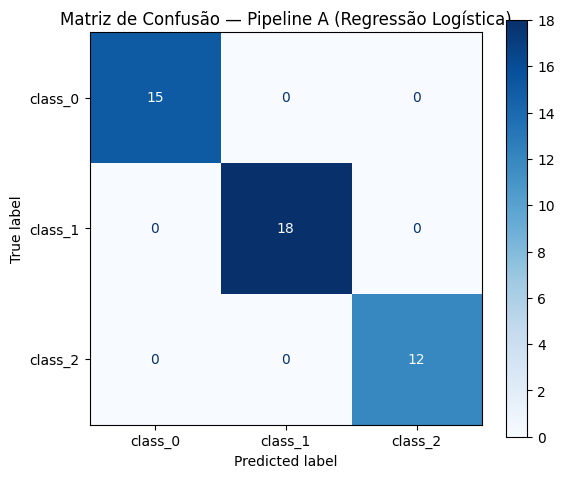


Matriz de Confusão (valores):
         class_0  class_1  class_2
class_0       15        0        0
class_1        0       18        0
class_2        0        0       12


In [6]:
from sklearn.metrics import accuracy_score, f1_score

acc_a = accuracy_score(y_test, y_pred_a)
acc_b = accuracy_score(y_test, y_pred_b)
print(f"Acurácia no teste - Pipeline A (LogReg): {acc_a:.4f}")
print(f"Acurácia no teste - Pipeline B (KNN)   : {acc_b:.4f}")
print(f"F1-macro no teste - Pipeline A: {f1_score(y_test, y_pred_a, average='macro'):.4f}")
print(f"F1-macro no teste - Pipeline B: {f1_score(y_test, y_pred_b, average='macro'):.4f}")
if scores_a.mean() >= scores_b.mean():
    melhor_nome = "Pipeline A (Regressão Logística)"
    melhor_modelo = pipeline_a
    y_pred_melhor = y_pred_a
else:
    melhor_nome = "Pipeline B (KNN, k=5)"
    melhor_modelo = pipeline_b
    y_pred_melhor = y_pred_b
print(f"\n>>> Melhor modelo (média CV): {melhor_nome}")
cm = confusion_matrix(y_test, y_pred_melhor)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=wine.target_names)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title(f'Matriz de Confusão — {melhor_nome}')
plt.tight_layout()
plt.show()
print("\nMatriz de Confusão (valores):")
print(pd.DataFrame(cm, index=wine.target_names, columns=wine.target_names))